In [1]:
import glob
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.util as cutil
from scipy import stats
import seaborn as sns

import numpy as np
time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)

def calculate_djf_mean(ds):
    ds_seasons = ds.resample(time='QE-FEB').mean()
    ds_djf = ds_seasons.sel(time=(ds_seasons['time.season'] == 'DJF'))
    return ds_djf

def load_data(path):
    ens = []
    ds = []
    for p in glob.glob(path):
        ens.append(p.split('/')[-1].split('_')[4])
        ds.append(xr.open_dataset(p))
    data = xr.concat(ds, dim='ens')
    data['ens'] = ens

    return data

def global_mean(data, lat='lat', lon='lon'):
    weights_lat_model = np.cos(np.deg2rad(data.lat))
    try:
        mean = data.weighted(weights_lat_model).mean([lat, lon])
    except ValueError:
        mean = data.weighted(weights_lat_model).mean([lat])
    return mean

def get_sign(diff, dim='model'):
    data_sign = np.sign(diff)
    mean_sign = np.sign(diff.mean(dim))
    return (data_sign == mean_sign).sum(dim)


def colorbar(mappable):
    from mpl_toolkits.axes_grid1 import make_axes_locatable
    import matplotlib.pyplot as plt
    last_axes = plt.gca()
    ax = mappable.axes
    fig = ax.figure
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="5%", pad=0.05)
    cbar = fig.colorbar(mappable, cax=cax)
    plt.sca(last_axes)
    return cbar

In [2]:
nam_flags = pd.read_csv('/home/kperny/VolMIP_stratosphere/tab/nam_flags.csv')
nam_flags = nam_flags.set_index(['model', 'realization'])

In [3]:
path = "/sto4/data/Intermediate/VolMIP/pinatubo-full/"
path_piControl = "/sto4/data/Intermediate/VolMIP/piControl/"
models = ['CanESM5', 'GISS-E2-1-G', 'IPSL-CM6A-LR', 'MPI-ESM1-2-LR', 'MIROC-ES2L'] # , 'UKESM1-0-LL']
plotdir = '/home/kperny/VolMIP_stratosphere/plots/NAM/'
percentage = 0.75
sign= percentage * len(models)

In [4]:
lat =[-87.863799, -85.096527, -82.312913, -79.525607, -76.7369  , -73.947515,
       -71.157752, -68.367756, -65.577607, -62.787352, -59.99702 , -57.206632,
       -54.4162  , -51.625734, -48.835241, -46.044727, -43.254195, -40.463648,
       -37.67309 , -34.882521, -32.091944, -29.30136 , -26.510769, -23.720174,
       -20.929574, -18.138971, -15.348365, -12.557756,  -9.767146,  -6.976534,
        -4.185921,  -1.395307,   1.395307,   4.185921,   6.976534,   9.767146,
        12.557756,  15.348365,  18.138971,  20.929574,  23.720174,  26.510769,
        29.30136 ,  32.091944,  34.882521,  37.67309 ,  40.463648,  43.254195,
        46.044727,  48.835241,  51.625734,  54.4162  ,  57.206632,  59.99702 ,
        62.787352,  65.577607,  68.367756,  71.157752,  73.947515,  76.7369  ,
        79.525607,  82.312913,  85.096527,  87.863799]
lon = [  0.    ,   2.8125,   5.625 ,   8.4375,  11.25  ,  14.0625,  16.875 ,
        19.6875,  22.5   ,  25.3125,  28.125 ,  30.9375,  33.75  ,  36.5625,
        39.375 ,  42.1875,  45.    ,  47.8125,  50.625 ,  53.4375,  56.25  ,
        59.0625,  61.875 ,  64.6875,  67.5   ,  70.3125,  73.125 ,  75.9375,
        78.75  ,  81.5625,  84.375 ,  87.1875,  90.    ,  92.8125,  95.625 ,
        98.4375, 101.25  , 104.0625, 106.875 , 109.6875, 112.5   , 115.3125,
       118.125 , 120.9375, 123.75  , 126.5625, 129.375 , 132.1875, 135.    ,
       137.8125, 140.625 , 143.4375, 146.25  , 149.0625, 151.875 , 154.6875,
       157.5   , 160.3125, 163.125 , 165.9375, 168.75  , 171.5625, 174.375 ,
       177.1875, 180.    , 182.8125, 185.625 , 188.4375, 191.25  , 194.0625,
       196.875 , 199.6875, 202.5   , 205.3125, 208.125 , 210.9375, 213.75  ,
       216.5625, 219.375 , 222.1875, 225.    , 227.8125, 230.625 , 233.4375,
       236.25  , 239.0625, 241.875 , 244.6875, 247.5   , 250.3125, 253.125 ,
       255.9375, 258.75  , 261.5625, 264.375 , 267.1875, 270.    , 272.8125,
       275.625 , 278.4375, 281.25  , 284.0625, 286.875 , 289.6875, 292.5   ,
       295.3125, 298.125 , 300.9375, 303.75  , 306.5625, 309.375 , 312.1875,
       315.    , 317.8125, 320.625 , 323.4375, 326.25  , 329.0625, 331.875 ,
       334.6875, 337.5   , 340.3125, 343.125 , 345.9375, 348.75  , 351.5625,
       354.375 , 357.1875]

# SURFACE

In [26]:
clim_ds = []
ano_picontrol = []
ano_volc = []
ano_volccorr = []
for i, model in enumerate(models): 
    clim = xr.open_dataset(glob.glob(path_piControl + model + '/tas_clim-djf_' + model + '*.nc')[0])
    clim_ds.append(clim.interp(lat=lat, lon=lon).tas)

    picontrol =  calculate_djf_mean(xr.open_dataset(glob.glob(path_piControl + model + '/tas_Amon_' + model + '_*.nc')[0]))
    picontrol['time'] = pd.date_range(str(picontrol.time[0].values).split('-')[0], str(int(str(picontrol.time[-1].values).split('-')[0]) +1), freq='YS-FEB',unit='s')

    pnaop = picontrol.sel(time=nam_flags.where(nam_flags.flag_1000_pi==1).dropna().loc[model]['year'].values, method='nearest').squeeze()
    pnaon = picontrol.sel(time=nam_flags.where(nam_flags.flag_1000_pi==-1).dropna().loc[model]['year'].values, method='nearest').squeeze()
    pnaonn = picontrol.sel(time=nam_flags.where(nam_flags.flag_1000_pi==0).dropna().loc[model]['year'].values, method='nearest').squeeze()

    tmp = xr.concat([pnaop, pnaon, pnaonn], dim='NAO')
    tmp['NAO'] = ['NAO+', 'NAO-', 'NAO0']
    # ano = tmp - clim
    ano_picontrol.append(tmp.interp(lat=lat, lon=lon))

    volc = load_data(path + model + '/tas_Amon_*.nc').squeeze()
    vnaop = volc.sel(ens=nam_flags.where(nam_flags.flag_1000_volc==1).dropna().loc[model].index, time=slice('1991-12','1992-02')).mean('time').squeeze()
    vnaon = volc.sel(ens=nam_flags.where(nam_flags.flag_1000_volc==-1).dropna().loc[model].index, time=slice('1991-12','1992-02')).mean('time').squeeze()
    vnaonn = volc.sel(ens=nam_flags.where(nam_flags.flag_1000_volc==0).dropna().loc[model].index, time=slice('1991-12','1992-02')).mean('time').squeeze()

    tmp = xr.concat([vnaop, vnaon, vnaonn], dim='NAO')
    tmp['NAO'] = ['NAO+', 'NAO-', 'NAO0']
    # ano = tmp - clim
    ano_volc.append(tmp.interp(lat=lat, lon=lon))

picontrol = xr.concat(ano_picontrol, dim='model') 
picontrol['model'] = models
volc = xr.concat(ano_volc, dim='model') 
volc['model'] = models
clim = xr.concat(clim_ds, dim='model')
clim['model'] = models

/tmp/ipykernel_760371/2535389862.py:9: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  picontrol =  calculate_djf_mean(xr.open_dataset(glob.glob(path_piControl + model + '/tas_Amon_' + model + '_*.nc')[0]))
/tmp/ipykernel_760371/2535389862.py:9: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  picontrol =  calculate_djf_mean(xr.open_dataset(glob.glob(path_piControl + model + '/tas_Amon_' + model + '_*.nc')[0]))
/tmp/ipykernel_760371/2123323486.py:23: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime 

/qic/Kathi/micromamba/envs/standard/lib/python3.10/site-packages/scipy/stats/_axis_nan_policy.py:430: RuntimeWarning: ks_2samp: Exact calculation unsuccessful. Switching to method=asymp.
  return hypotest_fun_in(*args, **kwds)
/qic/Kathi/micromamba/envs/standard/lib/python3.10/site-packages/scipy/stats/_axis_nan_policy.py:430: RuntimeWarning: ks_2samp: Exact calculation unsuccessful. Switching to method=asymp.
  return hypotest_fun_in(*args, **kwds)
/qic/Kathi/micromamba/envs/standard/lib/python3.10/site-packages/scipy/stats/_axis_nan_policy.py:430: RuntimeWarning: ks_2samp: Exact calculation unsuccessful. Switching to method=asymp.
  return hypotest_fun_in(*args, **kwds)


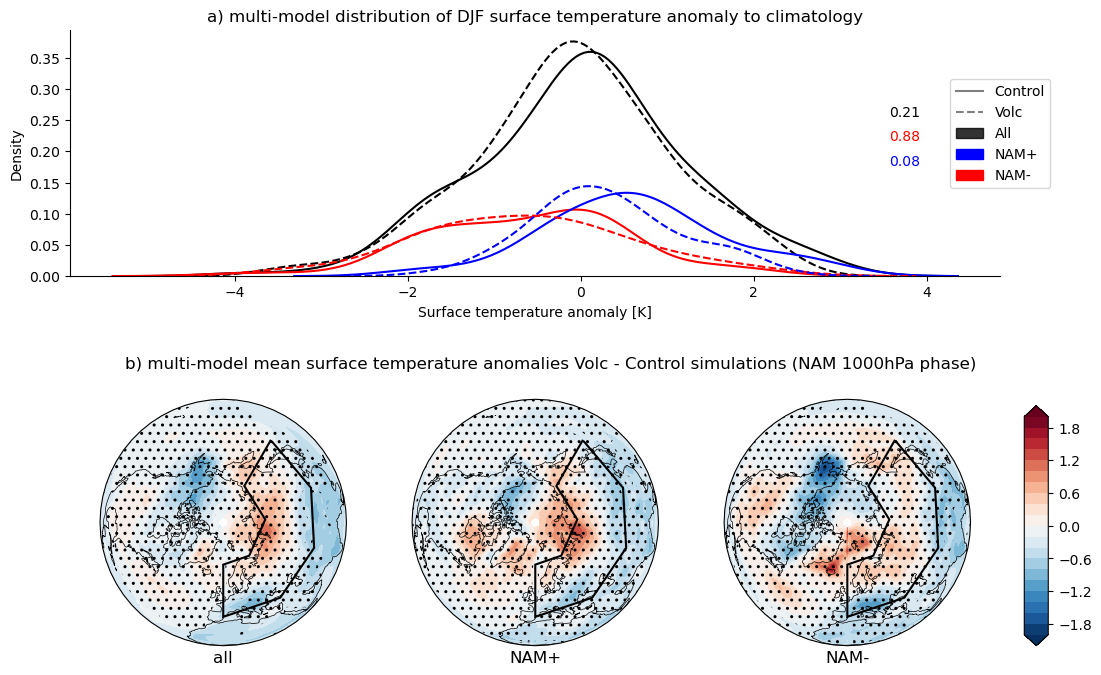

In [27]:
# polvani_box = (lat = (40,70),lon=(0,150))
df_pi = global_mean((picontrol.tas - clim).sel(lat=slice(40,70), lon=slice(0,150))).to_dataframe().reset_index().dropna()
df_volc = global_mean((volc.tas - clim).sel(lat=slice(40,70), lon=slice(0,150))).to_dataframe().reset_index().dropna()


fig = plt.figure(figsize=(12, 8))
ax1 = plt.subplot(2,1,1)
ax2 = plt.subplot(2,3,4, projection=ccrs.Orthographic(central_latitude=90))
ax3 = plt.subplot(2,3,5, projection=ccrs.Orthographic(central_latitude=90))
ax4 = plt.subplot(2,3,6, projection=ccrs.Orthographic(central_latitude=90))
axes = [ax1, ax2, ax3, ax4]

sns.kdeplot(df_pi, x='tas', c='k', ax=ax1, legend=False)
sns.kdeplot(df_volc, x='tas', c='k', linestyle='--', ax=ax1, legend=False)

sns.kdeplot(df_pi, x='tas', hue='NAO', palette=['blue', 'red', 'grey'], ax=ax1, legend=False)
lines = sns.kdeplot(df_volc, x='tas', hue='NAO',  palette=['blue', 'red', 'grey'],linestyle='--', ax=ax1, legend=False)
lines.lines[5].remove()
lines.lines[2].remove()

ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.set_xlabel('Surface temperature anomaly [K]')

from matplotlib.lines import Line2D
import matplotlib.patches as mpatches
line_piControl = Line2D([0], [0], label='Control', color='grey')
line_volc = Line2D([0], [0], label='Volc', color='grey', linestyle='--')
all = mpatches.Patch(color='k', alpha=0.8, label='All')
ponao = mpatches.Patch(color='blue', label='NAM+')
negnao = mpatches.Patch(color='red', label='NAM-')
fig.legend(handles=[line_piControl, line_volc, all, ponao, negnao], loc='center', bbox_to_anchor=(0.9, 0.75))

ax1.text(0.88, 0.65, str(stats.kstest(df_volc.tas.dropna().values, df_pi.tas.dropna().values)[1].round(2)), transform=ax1.transAxes, c='k')
ax1.text(0.88, 0.55, str(stats.kstest(df_volc.where(df_volc.NAO == 'NAO-').dropna().tas.values, df_pi.where(df_pi.NAO == 'NAO-').dropna().tas.values)[1].round(2)), transform=ax1.transAxes, c='r')
ax1.text(0.88, 0.45, str(stats.kstest(df_volc.where(df_volc.NAO == 'NAO+').dropna().tas.values, df_pi.where(df_pi.NAO == 'NAO+').dropna().tas.values)[1].round(2)), transform=ax1.transAxes, c='b')

#### Plot polar 2D maps

diff = volc.tas.mean('ens') - picontrol.tas.mean('time') 
sign_data = get_sign(diff)
levels = np.linspace(-2,2,21)

cdata, clon, clat = cutil.add_cyclic(diff.mean(['NAO', 'model']), diff.lon, diff.lat)
ax2.contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())
sign = stats.kstest((volc.tas.mean('ens').mean('NAO') - clim).values, (picontrol.tas.mean('time').mean('NAO') - clim).values)[1]
cdata, clon, clat = cutil.add_cyclic(sign, diff.lon, diff.lat)
ax2.contourf(clon, clat, cdata, [0.05,1], cmap=plt.get_cmap("gray"), hatches=['..',None], alpha=0.01, transform=ccrs.PlateCarree())
ax2.coastlines(linewidth=0.5)
ax2.set_title('all', y=-0.1)

cdata, clon, clat = cutil.add_cyclic(diff.sel(NAO='NAO+').mean('model'), diff.lon, diff.lat)
ax3.contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())
sign = stats.kstest((volc.tas.sel(NAO='NAO+').mean('ens')  - clim).values, (picontrol.tas.sel(NAO='NAO+').mean('time')- clim).values)[1]
cdata, clon, clat = cutil.add_cyclic(sign, diff.lon, diff.lat)
ax3.contourf(clon, clat, cdata, [0.05,1], cmap=plt.get_cmap("gray"), hatches=['..',None], alpha=0.01, transform=ccrs.PlateCarree())
ax3.coastlines(linewidth=0.5)
ax3.set_title('NAM+', y=-0.1)

cdata, clon, clat = cutil.add_cyclic(diff.sel(NAO='NAO-').mean('model'), diff.lon, diff.lat)
c = ax4.contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())
sign = stats.kstest((volc.tas.sel(NAO='NAO-').mean('ens')  - clim).values, (picontrol.tas.sel(NAO='NAO-').mean('time')- clim).values)[1]
cdata, clon, clat = cutil.add_cyclic(sign, diff.lon, diff.lat)
ax4.contourf(clon, clat, cdata, [0.05,1], cmap=plt.get_cmap("gray"), hatches=['..',None], alpha=0.01, transform=ccrs.PlateCarree())
ax4.coastlines(linewidth=0.5)
ax4.set_title('NAM-', y=-0.1)

fig.subplots_adjust(hspace=0.5, wspace=0.02)
ax1.set_title('a) multi-model distribution of DJF surface temperature anomaly to climatology')
plt.annotate('b) multi-model mean surface temperature anomalies Volc - Control simulations (NAM 1000hPa phase)', (0.5,0.45), fontsize=12,
             xycoords='subfigure fraction', horizontalalignment='center', verticalalignment='bottom')

ax2.add_patch(mpatches.Rectangle(xy=[0, 40], width=150, height=30,
                                facecolor='none', edgecolor='k', linewidth=1.5, 
                                transform=ccrs.PlateCarree()))

ax3.add_patch(mpatches.Rectangle(xy=[0, 40], width=150, height=30,
                                facecolor='none', edgecolor='k', linewidth=1.5,
                                transform=ccrs.PlateCarree()))

ax4.add_patch(mpatches.Rectangle(xy=[0, 40], width=150, height=30,
                                facecolor='none', edgecolor='k', linewidth=1.5,
                                transform=ccrs.PlateCarree()))

# add an axes, lower left corner in [0.83, 0.1] measured in figure coordinate with axes width 0.02 and height 0.8
cb_ax = fig.add_axes([0.92, 0.11, 0.02, 0.3])
cbar = fig.colorbar(c, cax=cb_ax)

plt.savefig(plotdir + 'figure4_1000.png', dpi=200, bbox_inches='tight')

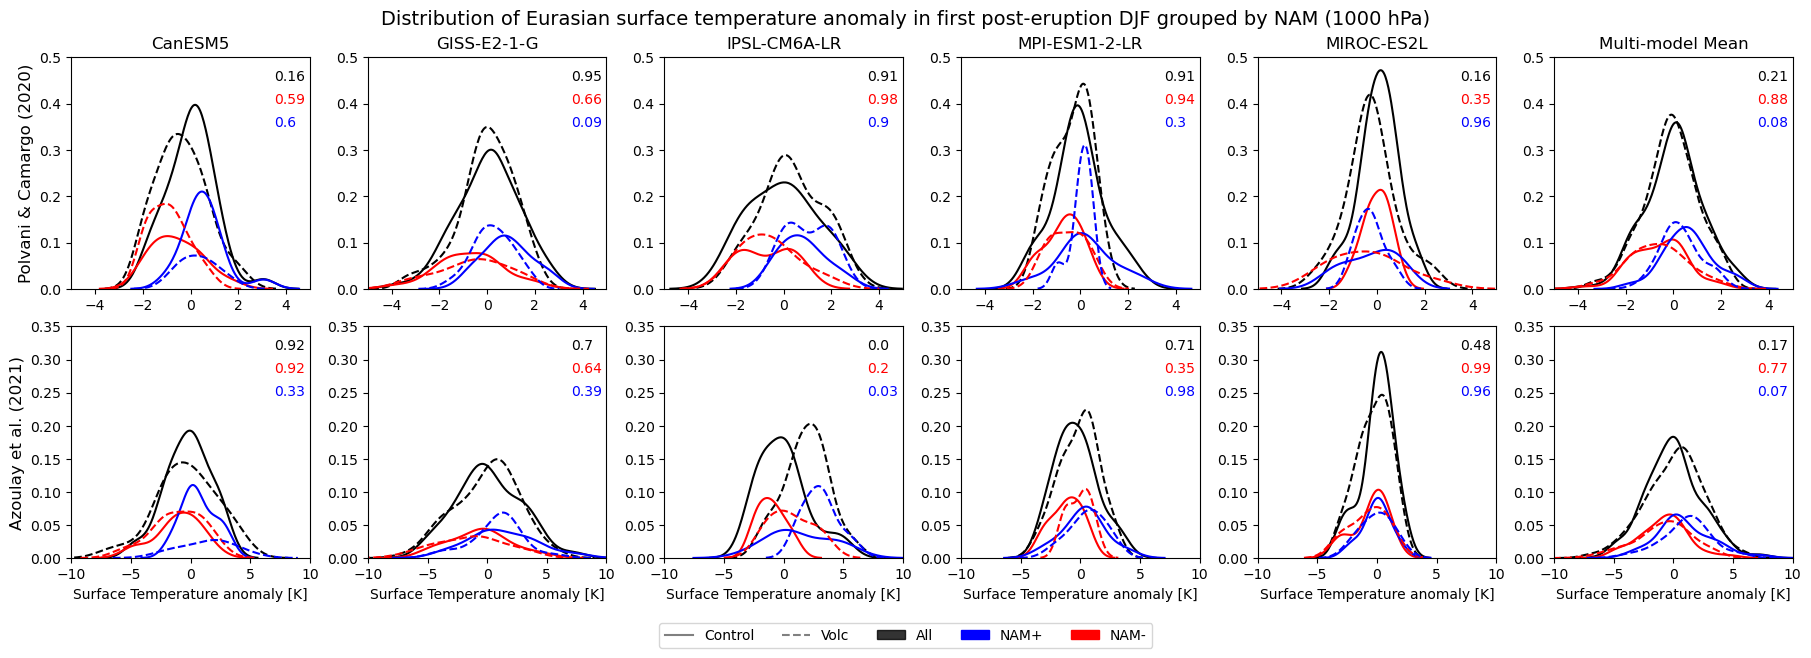

In [10]:
# polvani_box = (lat = (40,70),lon=(0,150))
dfp_pi = global_mean((picontrol.tas - clim).sel(lat=slice(40,70), lon=slice(0,150))).to_dataframe().reset_index().dropna()
dfp_volc = global_mean((volc.tas - clim).sel(lat=slice(40,70), lon=slice(0,150))).to_dataframe().reset_index().dropna()

# azoulay_box (lat=55-80, lon) (10-90))
dfa_pi = global_mean((picontrol.tas - clim).sel(lat=slice(55,80), lon=slice(10,90))).to_dataframe().reset_index().dropna()
dfa_volc = global_mean((volc.tas - clim).sel(lat=slice(55,80), lon=slice(10,90))).to_dataframe().reset_index().dropna()

fig, axs = plt.subplots(2,6, figsize=(18, 6), layout='constrained')

for i, model in enumerate(models):
    ax1 = axs[0,i]
    ax1.set_title(model)

    sns.kdeplot(dfp_pi.where(dfp_pi.model == model), x='tas', c='k', ax=ax1, legend=False)
    sns.kdeplot(dfp_volc.where(dfp_volc.model == model), x='tas', c='k', linestyle='--', ax=ax1, legend=False)

    sns.kdeplot(dfp_pi.where(dfp_pi.model == model), x='tas', hue='NAO', palette=['blue', 'red', 'grey'], ax=ax1, legend=False)
    lines = sns.kdeplot(dfp_volc.where(dfp_volc.model == model), x='tas', hue='NAO',  palette=['blue', 'red', 'grey'], linestyle='--', ax=ax1, legend=False)
    lines.lines[5].remove()
    lines.lines[2].remove()

    dfp_pi_model = dfp_pi.where(dfp_pi.model == model)
    dfp_volc_model = dfp_volc.where(dfp_volc.model == model)
    ax1.text(0.85, 0.9, str(stats.kstest(dfp_volc_model.tas.dropna().values, dfp_pi_model.tas.dropna().values)[1].round(2)), transform=ax1.transAxes, c='k')
    ax1.text(0.85, 0.8, str(stats.kstest(dfp_volc_model.where(dfp_volc_model.NAO == 'NAO-').dropna().tas.values, dfp_pi_model.where(dfp_pi_model.NAO == 'NAO-').dropna().tas.values)[1].round(2)), transform=ax1.transAxes, c='r')
    ax1.text(0.85, 0.7, str(stats.kstest(dfp_volc_model.where(dfp_volc_model.NAO == 'NAO+').dropna().tas.values, dfp_pi_model.where(dfp_pi_model.NAO == 'NAO+').dropna().tas.values)[1].round(2)), transform=ax1.transAxes, c='b')

    ax1.set_xlim(-5,5)
    ax1.set_ylim(0, 0.5)
    ax1.set_ylabel('')
    ax1.set_xlabel('')


    ax2 = axs[1,i]
    sns.kdeplot(dfa_pi.where(dfa_pi.model == model), x='tas', c='k', ax=ax2, legend=False)
    sns.kdeplot(dfa_volc.where(dfa_volc.model == model), x='tas', c='k', linestyle='--', ax=ax2, legend=False)

    sns.kdeplot(dfa_pi.where(dfa_pi.model == model), x='tas', hue='NAO', palette=['blue', 'red', 'grey'], ax=ax2, legend=False)
    lines = sns.kdeplot(dfa_volc.where(dfa_volc.model == model), x='tas', hue='NAO',  palette=['blue', 'red', 'grey'], linestyle='--', ax=ax2, legend=False)
    lines.lines[5].remove()
    lines.lines[2].remove()

    dfa_pi_model = dfa_pi.where(dfa_pi.model == model)
    dfa_volc_model = dfa_volc.where(dfa_volc.model == model)
    ax2.text(0.85, 0.9, str(stats.kstest(dfa_volc_model.tas.dropna().values, dfa_pi_model.tas.dropna().values)[1].round(2)), transform=ax2.transAxes, c='k')
    ax2.text(0.85, 0.8, str(stats.kstest(dfa_volc_model.where(dfa_volc_model.NAO == 'NAO-').dropna().tas.values, dfa_pi_model.where(dfa_pi_model.NAO == 'NAO-').dropna().tas.values)[1].round(2)), transform=ax2.transAxes, c='r')
    ax2.text(0.85, 0.7, str(stats.kstest(dfa_volc_model.where(dfa_volc_model.NAO == 'NAO+').dropna().tas.values, dfa_pi_model.where(dfa_pi_model.NAO == 'NAO+').dropna().tas.values)[1].round(2)), transform=ax2.transAxes, c='b')

    ax2.set_xlim(-10,10)
    ax2.set_ylim(0, 0.35)
    ax2.set_ylabel('')
    ax2.set_xlabel('Surface Temperature anomaly [K]')

ax1 = axs[0,5]
ax1.set_title('Multi-model Mean')
sns.kdeplot(dfp_pi, x='tas', c='k', ax=ax1, legend=False)
sns.kdeplot(dfp_volc, x='tas', c='k', linestyle='--', ax=ax1, legend=False)

sns.kdeplot(dfp_pi, x='tas', hue='NAO', palette=['blue', 'red', 'grey'], ax=ax1, legend=False)
lines = sns.kdeplot(dfp_volc, x='tas', hue='NAO',  palette=['blue', 'red', 'grey'], linestyle='--', ax=ax1, legend=False)
lines.lines[5].remove()
lines.lines[2].remove()

ax1.text(0.85, 0.9, str(stats.kstest(dfp_volc.tas.dropna().values, dfp_pi.tas.dropna().values)[1].round(2)), transform=ax1.transAxes, c='k')
ax1.text(0.85, 0.8, str(stats.kstest(dfp_volc.where(dfp_volc.NAO == 'NAO-').dropna().tas.values, dfp_pi.where(dfp_pi.NAO == 'NAO-').dropna().tas.values)[1].round(2)), transform=ax1.transAxes, c='r')
ax1.text(0.85, 0.7, str(stats.kstest(dfp_volc.where(dfp_volc.NAO == 'NAO+').dropna().tas.values, dfp_pi.where(dfp_pi.NAO == 'NAO+').dropna().tas.values)[1].round(2)), transform=ax1.transAxes, c='b')

ax1.set_xlim(-5,5)
ax1.set_ylim(0, 0.5)
ax1.set_ylabel('')
ax1.set_xlabel('')

ax2 = axs[1,5]
sns.kdeplot(dfa_pi, x='tas', c='k', ax=ax2, legend=False)
sns.kdeplot(dfa_volc, x='tas', c='k', linestyle='--', ax=ax2, legend=False)

sns.kdeplot(dfa_pi, x='tas', hue='NAO', palette=['blue', 'red', 'grey'], ax=ax2, legend=False)
lines = sns.kdeplot(dfa_volc, x='tas', hue='NAO',  palette=['blue', 'red', 'grey'], linestyle='--', ax=ax2, legend=False)
lines.lines[5].remove()
lines.lines[2].remove()

ax2.text(0.85, 0.9, str(stats.kstest(dfa_volc.tas.dropna().values, dfa_pi.tas.dropna().values)[1].round(2)), transform=ax2.transAxes, c='k')
ax2.text(0.85, 0.8, str(stats.kstest(dfa_volc.where(dfa_volc.NAO == 'NAO-').dropna().tas.values, dfa_pi.where(dfa_pi.NAO == 'NAO-').dropna().tas.values)[1].round(2)), transform=ax2.transAxes, c='r')
ax2.text(0.85, 0.7, str(stats.kstest(dfa_volc.where(dfa_volc.NAO == 'NAO+').dropna().tas.values, dfa_pi.where(dfa_pi.NAO == 'NAO+').dropna().tas.values)[1].round(2)), transform=ax2.transAxes, c='b')

ax2.set_xlim(-10,10)
ax2.set_ylim(0, 0.35)
ax2.set_ylabel('')
ax2.set_xlabel('Surface Temperature anomaly [K]')

from matplotlib.lines import Line2D
import matplotlib.patches as mpatches
line_piControl = Line2D([0], [0], label='Control', color='grey')
line_volc = Line2D([0], [0], label='Volc', color='grey', linestyle='--')
all = mpatches.Patch(color='k', alpha=0.8, label='All')
ponao = mpatches.Patch(color='blue', label='NAM+')
negnao = mpatches.Patch(color='red', label='NAM-')
fig.legend(handles=[line_piControl, line_volc, all, ponao, negnao], loc='center', ncol=5, bbox_to_anchor=(0.5, -0.05))

axs[0,0].set_ylabel('Polvani & Camargo (2020)', fontsize=12)
axs[1,0].set_ylabel('Azoulay et al. (2021)', fontsize=12)
plt.suptitle("Distribution of Eurasian surface temperature anomaly in first post-eruption DJF grouped by NAM (1000 hPa)", fontsize=14)
plt.savefig(plotdir + 'supp7_1000.png', dpi=200, bbox_inches='tight')


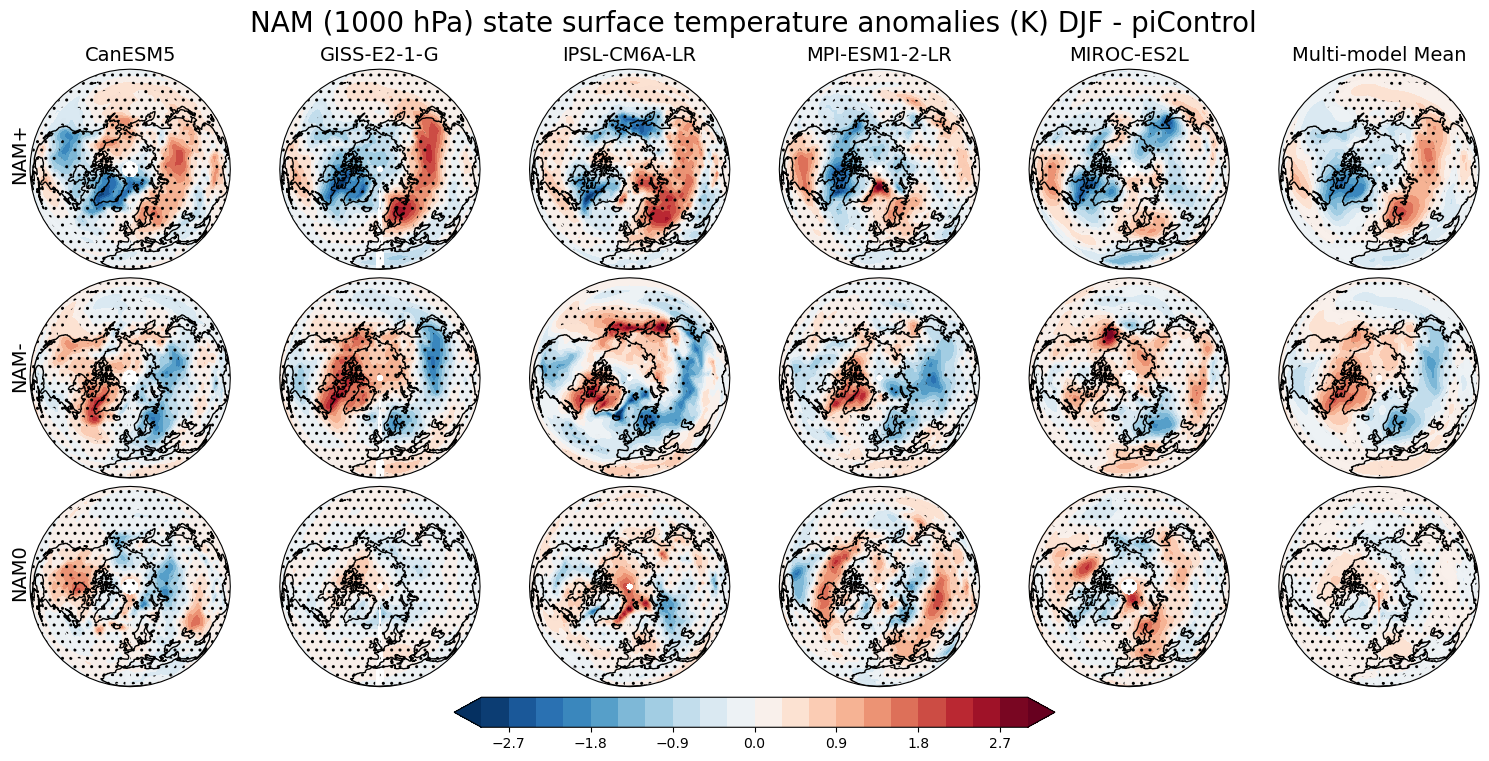

In [9]:
# all models volc - picontrol (NAO+ / NAO-)
fig, axs = plt.subplots(3,6, figsize=(15,7.5), subplot_kw={'projection': ccrs.Orthographic(central_latitude=90)}, layout='constrained')
levels = np.linspace(-3,3,21)

percentage = 0.75
num_models = percentage * len(models)

clim_dict = []
for i, model in enumerate(models):
    ano = picontrol.sel(model=model).tas - clim.sel(model=model)

    # NAO + 
    cdata, clon, clat = cutil.add_cyclic((ano.sel(NAO='NAO+').mean('time')), ano.lon, ano.lat)
    c = axs[0,i].contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())
    axs[0,i].contourf(ano.lon, ano.lat, get_sign(ano.sel(NAO='NAO+').dropna('time', how='all'), 'time'), [0, len(ano.sel(NAO='NAO+').dropna('time', how='all').time) * percentage],
                      cmap=plt.get_cmap("gray"), hatches=['..',None], alpha=0.01, transform=ccrs.PlateCarree())
    
    # NAO - 
    cdata, clon, clat = cutil.add_cyclic((ano.sel(NAO='NAO-').mean('time')), ano.lon, ano.lat)
    c = axs[1,i].contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())
    axs[1,i].contourf(ano.lon, ano.lat, get_sign(ano.sel(NAO='NAO-').dropna('time', how='all'), 'time'), [0, len(ano.sel(NAO='NAO-').dropna('time', how='all').time) * percentage],
                      cmap=plt.get_cmap("gray"), hatches=['..',None], alpha=0.01, transform=ccrs.PlateCarree())

    # NAO 0 
    cdata, clon, clat = cutil.add_cyclic((ano.sel(NAO='NAO0').mean('time')), ano.lon, ano.lat)
    c = axs[2,i].contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())
    axs[2,i].contourf(ano.lon, ano.lat, get_sign(ano.sel(NAO='NAO0').dropna('time', how='all'), 'time'), [0, len(ano.sel(NAO='NAO0').dropna('time', how='all').time) * percentage],
                      cmap=plt.get_cmap("gray"), hatches=['..',None], alpha=0.01, transform=ccrs.PlateCarree())

    axs[0,i].set_title(model, fontsize=14)

axs[0,5].set_title('Multi-model Mean', fontsize=14)
ano = picontrol.tas - clim

# NAO + 
cdata, clon, clat = cutil.add_cyclic((ano.sel(NAO='NAO+').mean(['time', 'model'])), ano.lon, ano.lat)
c = axs[0,i+1].contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())
axs[0,i+1].contourf(ano.lon, ano.lat, get_sign(ano.sel(NAO='NAO+').mean('time')),[0, num_models], cmap=plt.get_cmap("gray"), hatches=['..',None], alpha=0.01, transform=ccrs.PlateCarree())

# NAO -
cdata, clon, clat = cutil.add_cyclic((ano.sel(NAO='NAO-').mean(['time', 'model'])), ano.lon, ano.lat)
c = axs[1,i+1].contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())
axs[1,i+1].contourf(ano.lon, ano.lat, get_sign(ano.sel(NAO='NAO-').mean('time')),[0, num_models], cmap=plt.get_cmap("gray"), hatches=['..',None], alpha=0.01, transform=ccrs.PlateCarree())

# NAO 0
cdata, clon, clat = cutil.add_cyclic((ano.sel(NAO='NAO0').mean(['time', 'model'])), ano.lon, ano.lat)
c = axs[2,i+1].contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())
axs[2,i+1].contourf(ano.lon, ano.lat, get_sign(ano.sel(NAO='NAO0').mean('time')),[0, num_models], cmap=plt.get_cmap("gray"), hatches=['..',None], alpha=0.01, transform=ccrs.PlateCarree())

for ax in axs.flatten():
    ax.coastlines()

axs[0,0].text(-0.1, 0.45, 'NAM+', transform=axs[0,0].transAxes, rotation=90, fontsize=14)
axs[1,0].text(-0.1, 0.45, 'NAM-', transform=axs[1,0].transAxes, rotation=90, fontsize=14)
axs[2,0].text(-0.1, 0.45, 'NAM0', transform=axs[2,0].transAxes, rotation=90, fontsize=14)

plt.colorbar(c, ax=axs[2,0:6], location='bottom')
plt.suptitle('NAM (1000 hPa) state surface temperature anomalies (K) DJF - piControl', fontsize=20)
plt.savefig(plotdir + 'supp3_1000.png', dpi=200)

# Stratosphere

In [21]:
clim_ds = []
ano_picontrol = []
ano_volc = []
ano_volccorr = []
for i, model in enumerate(models): 
    clim = xr.open_dataset(glob.glob(path_piControl + model + '/tas_clim-djf_' + model + '*.nc')[0])
    clim_ds.append(clim.interp(lat=lat, lon=lon).tas)

    picontrol =  calculate_djf_mean(xr.open_dataset(glob.glob(path_piControl + model + '/tas_Amon_' + model + '_*.nc')[0]))
    picontrol['time'] = pd.date_range(str(picontrol.time[0].values).split('-')[0], str(int(str(picontrol.time[-1].values).split('-')[0]) +1), freq='YS-FEB',unit='s')

    pnaop = picontrol.sel(time=nam_flags.where(nam_flags.flag_10_pi==1).dropna().loc[model]['year'].values, method='nearest').squeeze()
    pnaon = picontrol.sel(time=nam_flags.where(nam_flags.flag_10_pi==-1).dropna().loc[model]['year'].values, method='nearest').squeeze()
    pnaonn = picontrol.sel(time=nam_flags.where(nam_flags.flag_10_pi==0).dropna().loc[model]['year'].values, method='nearest').squeeze()

    tmp = xr.concat([pnaop, pnaon, pnaonn], dim='NAO')
    tmp['NAO'] = ['NAO+', 'NAO-', 'NAO0']
    # ano = tmp - clim
    ano_picontrol.append(tmp.interp(lat=lat, lon=lon))

    volc = load_data(path + model + '/tas_Amon_*.nc').squeeze()
    vnaop = volc.sel(ens=nam_flags.where(nam_flags.flag_10_volc==1).dropna().loc[model].index, time=slice('1991-12','1992-02')).mean('time').squeeze()
    vnaon = volc.sel(ens=nam_flags.where(nam_flags.flag_10_volc==-1).dropna().loc[model].index, time=slice('1991-12','1992-02')).mean('time').squeeze()
    vnaonn = volc.sel(ens=nam_flags.where(nam_flags.flag_10_volc==0).dropna().loc[model].index, time=slice('1991-12','1992-02')).mean('time').squeeze()

    try:
        tmp = xr.concat([vnaop, vnaon, vnaonn], dim='NAO')
    except:
        try:
            vnaonn = vnaonn.expand_dims('ens')
            tmp = xr.concat([vnaop, vnaon, vnaonn], dim='NAO')
        except:
            vnaon = vnaon.expand_dims('ens')
            tmp = xr.concat([vnaop, vnaon, vnaonn], dim='NAO')
    tmp['NAO'] = ['NAO+', 'NAO-', 'NAO0']
    # ano = tmp - clim
    ano_volc.append(tmp.interp(lat=lat, lon=lon))

picontrol = xr.concat(ano_picontrol, dim='model') 
picontrol['model'] = models
volc = xr.concat(ano_volc, dim='model') 
volc['model'] = models
clim = xr.concat(clim_ds, dim='model')
clim['model'] = models

/tmp/ipykernel_760371/1735219013.py:9: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  picontrol =  calculate_djf_mean(xr.open_dataset(glob.glob(path_piControl + model + '/tas_Amon_' + model + '_*.nc')[0]))
/tmp/ipykernel_760371/1735219013.py:9: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  picontrol =  calculate_djf_mean(xr.open_dataset(glob.glob(path_piControl + model + '/tas_Amon_' + model + '_*.nc')[0]))
/tmp/ipykernel_760371/2123323486.py:23: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime 

/qic/Kathi/micromamba/envs/standard/lib/python3.10/site-packages/scipy/stats/_axis_nan_policy.py:430: RuntimeWarning: ks_2samp: Exact calculation unsuccessful. Switching to method=asymp.
  return hypotest_fun_in(*args, **kwds)
/qic/Kathi/micromamba/envs/standard/lib/python3.10/site-packages/scipy/stats/_axis_nan_policy.py:430: RuntimeWarning: ks_2samp: Exact calculation unsuccessful. Switching to method=asymp.
  return hypotest_fun_in(*args, **kwds)
/qic/Kathi/micromamba/envs/standard/lib/python3.10/site-packages/scipy/stats/_axis_nan_policy.py:430: RuntimeWarning: ks_2samp: Exact calculation unsuccessful. Switching to method=asymp.
  return hypotest_fun_in(*args, **kwds)


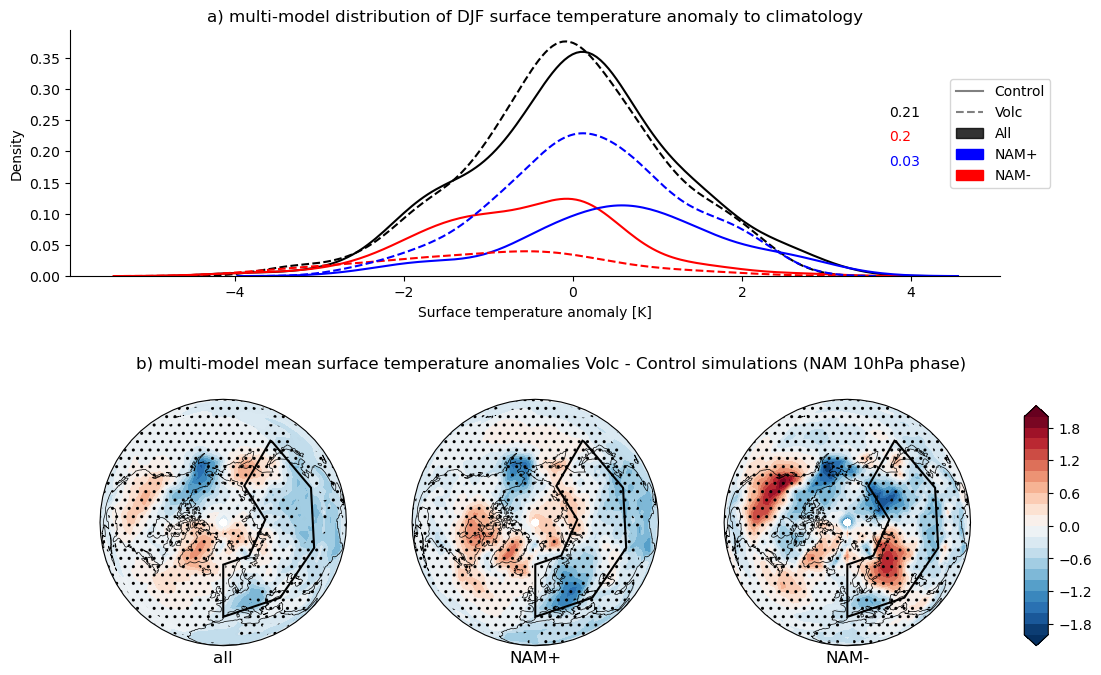

In [25]:
# polvani_box = (lat = (40,70),lon=(0,150))
df_pi = global_mean((picontrol.tas - clim).sel(lat=slice(40,70), lon=slice(0,150))).to_dataframe().reset_index().dropna()
df_volc = global_mean((volc.tas - clim).sel(lat=slice(40,70), lon=slice(0,150))).to_dataframe().reset_index().dropna()


fig = plt.figure(figsize=(12, 8))
ax1 = plt.subplot(2,1,1)
ax2 = plt.subplot(2,3,4, projection=ccrs.Orthographic(central_latitude=90))
ax3 = plt.subplot(2,3,5, projection=ccrs.Orthographic(central_latitude=90))
ax4 = plt.subplot(2,3,6, projection=ccrs.Orthographic(central_latitude=90))
axes = [ax1, ax2, ax3, ax4]

sns.kdeplot(df_pi, x='tas', c='k', ax=ax1, legend=False)
sns.kdeplot(df_volc, x='tas', c='k', linestyle='--', ax=ax1, legend=False)

sns.kdeplot(df_pi, x='tas', hue='NAO', palette=['blue', 'red', 'grey'], ax=ax1, legend=False)
lines = sns.kdeplot(df_volc, x='tas', hue='NAO',  palette=['blue', 'red', 'grey'],linestyle='--', ax=ax1, legend=False)
lines.lines[5].remove()
lines.lines[2].remove()

ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.set_xlabel('Surface temperature anomaly [K]')

from matplotlib.lines import Line2D
import matplotlib.patches as mpatches
line_piControl = Line2D([0], [0], label='Control', color='grey')
line_volc = Line2D([0], [0], label='Volc', color='grey', linestyle='--')
all = mpatches.Patch(color='k', alpha=0.8, label='All')
ponao = mpatches.Patch(color='blue', label='NAM+')
negnao = mpatches.Patch(color='red', label='NAM-')
fig.legend(handles=[line_piControl, line_volc, all, ponao, negnao], loc='center', bbox_to_anchor=(0.9, 0.75))

ax1.text(0.88, 0.65, str(stats.kstest(df_volc.tas.dropna().values, df_pi.tas.dropna().values)[1].round(2)), transform=ax1.transAxes, c='k')
ax1.text(0.88, 0.55, str(stats.kstest(df_volc.where(df_volc.NAO == 'NAO-').dropna().tas.values, df_pi.where(df_pi.NAO == 'NAO-').dropna().tas.values)[1].round(2)), transform=ax1.transAxes, c='r')
ax1.text(0.88, 0.45, str(stats.kstest(df_volc.where(df_volc.NAO == 'NAO+').dropna().tas.values, df_pi.where(df_pi.NAO == 'NAO+').dropna().tas.values)[1].round(2)), transform=ax1.transAxes, c='b')

#### Plot polar 2D maps

diff = volc.tas.mean('ens') - picontrol.tas.mean('time') 
sign_data = get_sign(diff)
levels = np.linspace(-2,2,21)

cdata, clon, clat = cutil.add_cyclic(diff.mean(['NAO', 'model']), diff.lon, diff.lat)
ax2.contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())
sign = stats.kstest((volc.tas.mean('ens').mean('NAO') - clim).values, (picontrol.tas.mean('time').mean('NAO') - clim).values)[1]
cdata, clon, clat = cutil.add_cyclic(sign, diff.lon, diff.lat)
ax2.contourf(clon, clat, cdata, [0.05,1], cmap=plt.get_cmap("gray"), hatches=['..',None], alpha=0.01, transform=ccrs.PlateCarree())
ax2.coastlines(linewidth=0.5)
ax2.set_title('all', y=-0.1)

cdata, clon, clat = cutil.add_cyclic(diff.sel(NAO='NAO+').mean('model'), diff.lon, diff.lat)
ax3.contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())
sign = stats.kstest((volc.tas.sel(NAO='NAO+').mean('ens')  - clim).values, (picontrol.tas.sel(NAO='NAO+').mean('time')- clim).values)[1]
cdata, clon, clat = cutil.add_cyclic(sign, diff.lon, diff.lat)
ax3.contourf(clon, clat, cdata, [0.05,1], cmap=plt.get_cmap("gray"), hatches=['..',None], alpha=0.01, transform=ccrs.PlateCarree())
ax3.coastlines(linewidth=0.5)
ax3.set_title('NAM+', y=-0.1)

cdata, clon, clat = cutil.add_cyclic(diff.sel(NAO='NAO-').mean('model'), diff.lon, diff.lat)
c = ax4.contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())
sign = stats.kstest((volc.tas.sel(NAO='NAO-').mean('ens')  - clim).values, (picontrol.tas.sel(NAO='NAO-').mean('time')- clim).values)[1]
cdata, clon, clat = cutil.add_cyclic(sign, diff.lon, diff.lat)
ax4.contourf(clon, clat, cdata, [0.05,1], cmap=plt.get_cmap("gray"), hatches=['..',None], alpha=0.01, transform=ccrs.PlateCarree())
ax4.coastlines(linewidth=0.5)
ax4.set_title('NAM-', y=-0.1)

fig.subplots_adjust(hspace=0.5, wspace=0.02)
ax1.set_title('a) multi-model distribution of DJF surface temperature anomaly to climatology')
plt.annotate('b) multi-model mean surface temperature anomalies Volc - Control simulations (NAM 10hPa phase)', (0.5,0.45), fontsize=12,
             xycoords='subfigure fraction', horizontalalignment='center', verticalalignment='bottom')

ax2.add_patch(mpatches.Rectangle(xy=[0, 40], width=150, height=30,
                                facecolor='none', edgecolor='k', linewidth=1.5, 
                                transform=ccrs.PlateCarree()))

ax3.add_patch(mpatches.Rectangle(xy=[0, 40], width=150, height=30,
                                facecolor='none', edgecolor='k', linewidth=1.5,
                                transform=ccrs.PlateCarree()))

ax4.add_patch(mpatches.Rectangle(xy=[0, 40], width=150, height=30,
                                facecolor='none', edgecolor='k', linewidth=1.5,
                                transform=ccrs.PlateCarree()))

# add an axes, lower left corner in [0.83, 0.1] measured in figure coordinate with axes width 0.02 and height 0.8
cb_ax = fig.add_axes([0.92, 0.11, 0.02, 0.3])
cbar = fig.colorbar(c, cax=cb_ax)

plt.savefig(plotdir + 'figure4_10.png', dpi=200, bbox_inches='tight')

/tmp/ipykernel_760371/151053055.py:19: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  lines = sns.kdeplot(dfp_volc.where(dfp_volc.model == model), x='tas', hue='NAO',  palette=['blue', 'red', 'grey'], linestyle='--', ax=ax1, legend=False)
/tmp/ipykernel_760371/151053055.py:40: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  lines = sns.kdeplot(dfa_volc.where(dfa_volc.model == model), x='tas', hue='NAO',  palette=['blue', 'red', 'grey'], linestyle='--', ax=ax2, legend=False)
/tmp/ipykernel_760371/151053055.py:19: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  lines = sns.kdeplot(dfp_volc.where(dfp_volc.model == model), x='tas', hue='NAO',  palette=['blue', 'red', 'grey'], linestyle='--', ax=ax1, legend=False)
/tmp/ipykernel_760371/151053055.py:40: UserWarning: Dataset has 0 vari

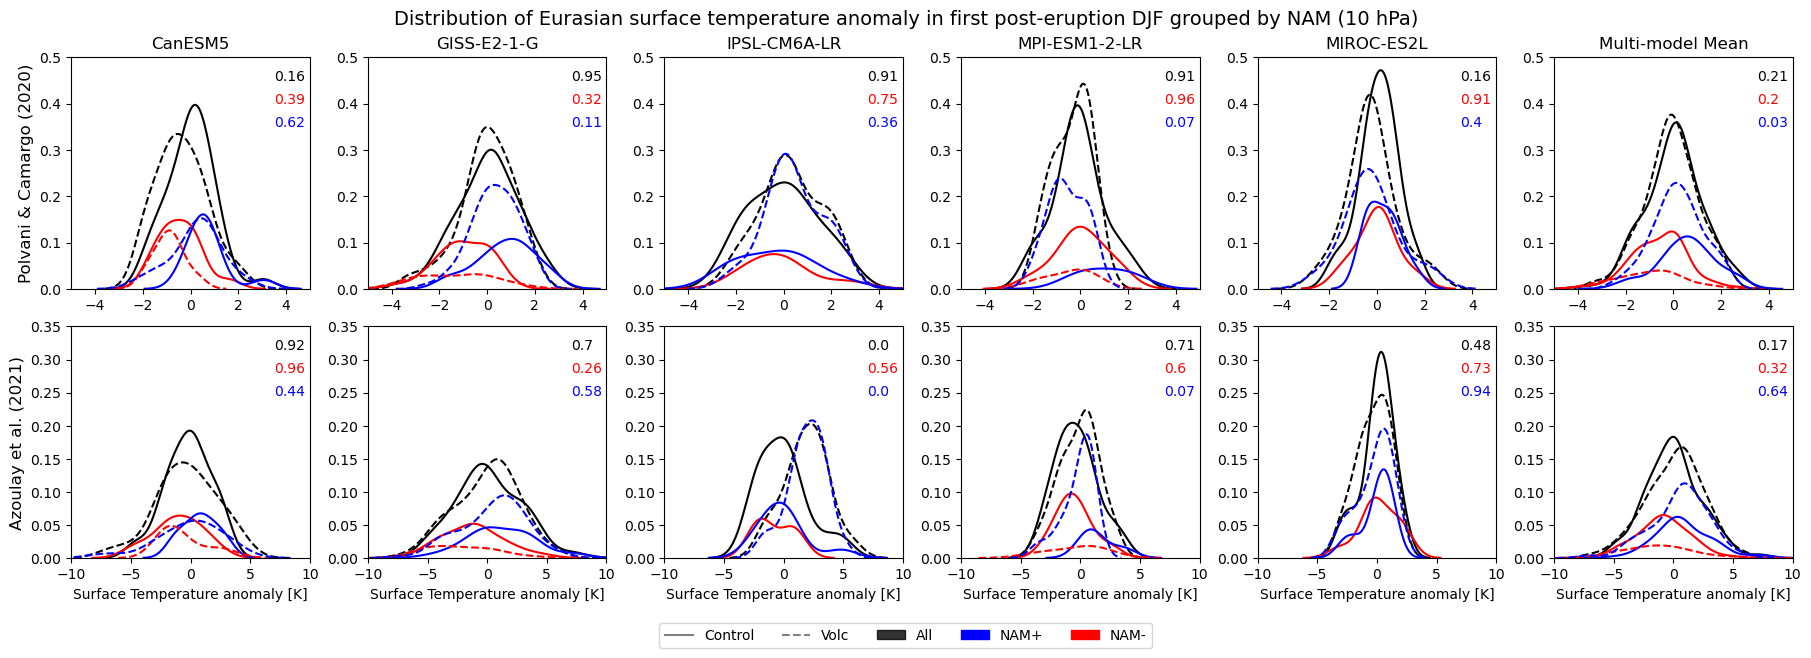

In [23]:
# polvani_box = (lat = (40,70),lon=(0,150))
dfp_pi = global_mean((picontrol.tas - clim).sel(lat=slice(40,70), lon=slice(0,150))).to_dataframe().reset_index().dropna()
dfp_volc = global_mean((volc.tas - clim).sel(lat=slice(40,70), lon=slice(0,150))).to_dataframe().reset_index().dropna()

# azoulay_box (lat=55-80, lon) (10-90))
dfa_pi = global_mean((picontrol.tas - clim).sel(lat=slice(55,80), lon=slice(10,90))).to_dataframe().reset_index().dropna()
dfa_volc = global_mean((volc.tas - clim).sel(lat=slice(55,80), lon=slice(10,90))).to_dataframe().reset_index().dropna()

fig, axs = plt.subplots(2,6, figsize=(18, 6), layout='constrained')

for i, model in enumerate(models):
    ax1 = axs[0,i]
    ax1.set_title(model)

    sns.kdeplot(dfp_pi.where(dfp_pi.model == model), x='tas', c='k', ax=ax1, legend=False)
    sns.kdeplot(dfp_volc.where(dfp_volc.model == model), x='tas', c='k', linestyle='--', ax=ax1, legend=False)

    sns.kdeplot(dfp_pi.where(dfp_pi.model == model), x='tas', hue='NAO', palette=['blue', 'red', 'grey'], ax=ax1, legend=False)
    lines = sns.kdeplot(dfp_volc.where(dfp_volc.model == model), x='tas', hue='NAO',  palette=['blue', 'red', 'grey'], linestyle='--', ax=ax1, legend=False)
    lines.lines[5].remove()
    lines.lines[2].remove()

    dfp_pi_model = dfp_pi.where(dfp_pi.model == model)
    dfp_volc_model = dfp_volc.where(dfp_volc.model == model)
    ax1.text(0.85, 0.9, str(stats.kstest(dfp_volc_model.tas.dropna().values, dfp_pi_model.tas.dropna().values)[1].round(2)), transform=ax1.transAxes, c='k')
    ax1.text(0.85, 0.8, str(stats.kstest(dfp_volc_model.where(dfp_volc_model.NAO == 'NAO-').dropna().tas.values, dfp_pi_model.where(dfp_pi_model.NAO == 'NAO-').dropna().tas.values)[1].round(2)), transform=ax1.transAxes, c='r')
    ax1.text(0.85, 0.7, str(stats.kstest(dfp_volc_model.where(dfp_volc_model.NAO == 'NAO+').dropna().tas.values, dfp_pi_model.where(dfp_pi_model.NAO == 'NAO+').dropna().tas.values)[1].round(2)), transform=ax1.transAxes, c='b')

    ax1.set_xlim(-5,5)
    ax1.set_ylim(0, 0.5)
    ax1.set_ylabel('')
    ax1.set_xlabel('')


    ax2 = axs[1,i]
    sns.kdeplot(dfa_pi.where(dfa_pi.model == model), x='tas', c='k', ax=ax2, legend=False)
    sns.kdeplot(dfa_volc.where(dfa_volc.model == model), x='tas', c='k', linestyle='--', ax=ax2, legend=False)

    sns.kdeplot(dfa_pi.where(dfa_pi.model == model), x='tas', hue='NAO', palette=['blue', 'red', 'grey'], ax=ax2, legend=False)
    lines = sns.kdeplot(dfa_volc.where(dfa_volc.model == model), x='tas', hue='NAO',  palette=['blue', 'red', 'grey'], linestyle='--', ax=ax2, legend=False)
    lines.lines[5].remove()
    lines.lines[2].remove()

    dfa_pi_model = dfa_pi.where(dfa_pi.model == model)
    dfa_volc_model = dfa_volc.where(dfa_volc.model == model)
    ax2.text(0.85, 0.9, str(stats.kstest(dfa_volc_model.tas.dropna().values, dfa_pi_model.tas.dropna().values)[1].round(2)), transform=ax2.transAxes, c='k')
    ax2.text(0.85, 0.8, str(stats.kstest(dfa_volc_model.where(dfa_volc_model.NAO == 'NAO-').dropna().tas.values, dfa_pi_model.where(dfa_pi_model.NAO == 'NAO-').dropna().tas.values)[1].round(2)), transform=ax2.transAxes, c='r')
    ax2.text(0.85, 0.7, str(stats.kstest(dfa_volc_model.where(dfa_volc_model.NAO == 'NAO+').dropna().tas.values, dfa_pi_model.where(dfa_pi_model.NAO == 'NAO+').dropna().tas.values)[1].round(2)), transform=ax2.transAxes, c='b')

    ax2.set_xlim(-10,10)
    ax2.set_ylim(0, 0.35)
    ax2.set_ylabel('')
    ax2.set_xlabel('Surface Temperature anomaly [K]')

ax1 = axs[0,5]
ax1.set_title('Multi-model Mean')
sns.kdeplot(dfp_pi, x='tas', c='k', ax=ax1, legend=False)
sns.kdeplot(dfp_volc, x='tas', c='k', linestyle='--', ax=ax1, legend=False)

sns.kdeplot(dfp_pi, x='tas', hue='NAO', palette=['blue', 'red', 'grey'], ax=ax1, legend=False)
lines = sns.kdeplot(dfp_volc, x='tas', hue='NAO',  palette=['blue', 'red', 'grey'], linestyle='--', ax=ax1, legend=False)
lines.lines[5].remove()
lines.lines[2].remove()

ax1.text(0.85, 0.9, str(stats.kstest(dfp_volc.tas.dropna().values, dfp_pi.tas.dropna().values)[1].round(2)), transform=ax1.transAxes, c='k')
ax1.text(0.85, 0.8, str(stats.kstest(dfp_volc.where(dfp_volc.NAO == 'NAO-').dropna().tas.values, dfp_pi.where(dfp_pi.NAO == 'NAO-').dropna().tas.values)[1].round(2)), transform=ax1.transAxes, c='r')
ax1.text(0.85, 0.7, str(stats.kstest(dfp_volc.where(dfp_volc.NAO == 'NAO+').dropna().tas.values, dfp_pi.where(dfp_pi.NAO == 'NAO+').dropna().tas.values)[1].round(2)), transform=ax1.transAxes, c='b')

ax1.set_xlim(-5,5)
ax1.set_ylim(0, 0.5)
ax1.set_ylabel('')
ax1.set_xlabel('')

ax2 = axs[1,5]
sns.kdeplot(dfa_pi, x='tas', c='k', ax=ax2, legend=False)
sns.kdeplot(dfa_volc, x='tas', c='k', linestyle='--', ax=ax2, legend=False)

sns.kdeplot(dfa_pi, x='tas', hue='NAO', palette=['blue', 'red', 'grey'], ax=ax2, legend=False)
lines = sns.kdeplot(dfa_volc, x='tas', hue='NAO',  palette=['blue', 'red', 'grey'], linestyle='--', ax=ax2, legend=False)
lines.lines[5].remove()
lines.lines[2].remove()

ax2.text(0.85, 0.9, str(stats.kstest(dfa_volc.tas.dropna().values, dfa_pi.tas.dropna().values)[1].round(2)), transform=ax2.transAxes, c='k')
ax2.text(0.85, 0.8, str(stats.kstest(dfa_volc.where(dfa_volc.NAO == 'NAO-').dropna().tas.values, dfa_pi.where(dfa_pi.NAO == 'NAO-').dropna().tas.values)[1].round(2)), transform=ax2.transAxes, c='r')
ax2.text(0.85, 0.7, str(stats.kstest(dfa_volc.where(dfa_volc.NAO == 'NAO+').dropna().tas.values, dfa_pi.where(dfa_pi.NAO == 'NAO+').dropna().tas.values)[1].round(2)), transform=ax2.transAxes, c='b')

ax2.set_xlim(-10,10)
ax2.set_ylim(0, 0.35)
ax2.set_ylabel('')
ax2.set_xlabel('Surface Temperature anomaly [K]')

from matplotlib.lines import Line2D
import matplotlib.patches as mpatches
line_piControl = Line2D([0], [0], label='Control', color='grey')
line_volc = Line2D([0], [0], label='Volc', color='grey', linestyle='--')
all = mpatches.Patch(color='k', alpha=0.8, label='All')
ponao = mpatches.Patch(color='blue', label='NAM+')
negnao = mpatches.Patch(color='red', label='NAM-')
fig.legend(handles=[line_piControl, line_volc, all, ponao, negnao], loc='center', ncol=5, bbox_to_anchor=(0.5, -0.05))

axs[0,0].set_ylabel('Polvani & Camargo (2020)', fontsize=12)
axs[1,0].set_ylabel('Azoulay et al. (2021)', fontsize=12)
plt.suptitle("Distribution of Eurasian surface temperature anomaly in first post-eruption DJF grouped by NAM (10 hPa)", fontsize=14)
plt.savefig(plotdir + 'supp7_10.png', dpi=200, bbox_inches='tight')


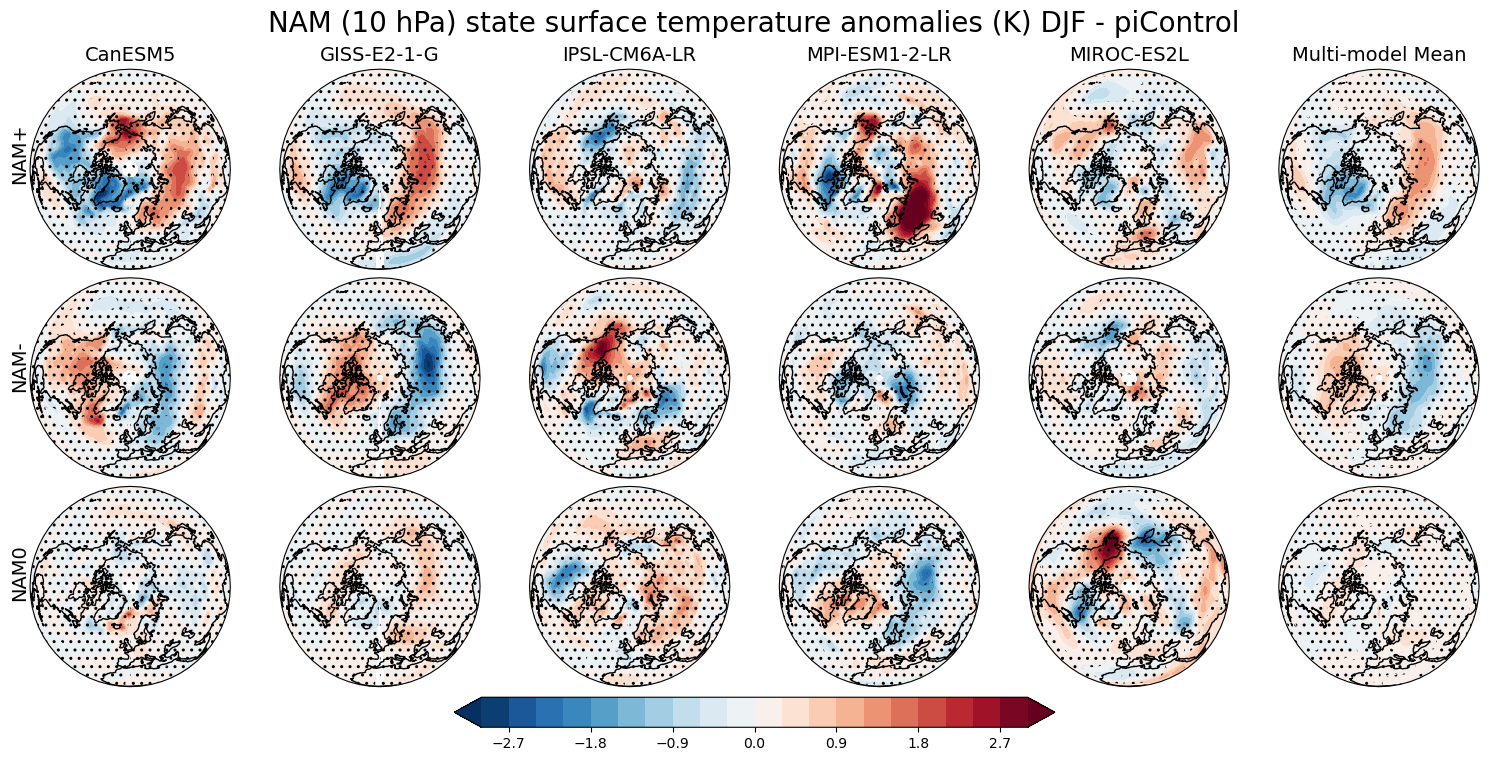

In [24]:
# all models volc - picontrol (NAO+ / NAO-)
fig, axs = plt.subplots(3,6, figsize=(15,7.5), subplot_kw={'projection': ccrs.Orthographic(central_latitude=90)}, layout='constrained')
levels = np.linspace(-3,3,21)

percentage = 0.75
num_models = percentage * len(models)

clim_dict = []
for i, model in enumerate(models):
    ano = picontrol.sel(model=model).tas - clim.sel(model=model)

    # NAO + 
    cdata, clon, clat = cutil.add_cyclic((ano.sel(NAO='NAO+').mean('time')), ano.lon, ano.lat)
    c = axs[0,i].contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())
    axs[0,i].contourf(ano.lon, ano.lat, get_sign(ano.sel(NAO='NAO+').dropna('time', how='all'), 'time'), [0, len(ano.sel(NAO='NAO+').dropna('time', how='all').time) * percentage],
                      cmap=plt.get_cmap("gray"), hatches=['..',None], alpha=0.01, transform=ccrs.PlateCarree())
    
    # NAO - 
    cdata, clon, clat = cutil.add_cyclic((ano.sel(NAO='NAO-').mean('time')), ano.lon, ano.lat)
    c = axs[1,i].contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())
    axs[1,i].contourf(ano.lon, ano.lat, get_sign(ano.sel(NAO='NAO-').dropna('time', how='all'), 'time'), [0, len(ano.sel(NAO='NAO-').dropna('time', how='all').time) * percentage],
                      cmap=plt.get_cmap("gray"), hatches=['..',None], alpha=0.01, transform=ccrs.PlateCarree())

    # NAO 0 
    cdata, clon, clat = cutil.add_cyclic((ano.sel(NAO='NAO0').mean('time')), ano.lon, ano.lat)
    c = axs[2,i].contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())
    axs[2,i].contourf(ano.lon, ano.lat, get_sign(ano.sel(NAO='NAO0').dropna('time', how='all'), 'time'), [0, len(ano.sel(NAO='NAO0').dropna('time', how='all').time) * percentage],
                      cmap=plt.get_cmap("gray"), hatches=['..',None], alpha=0.01, transform=ccrs.PlateCarree())

    axs[0,i].set_title(model, fontsize=14)

axs[0,5].set_title('Multi-model Mean', fontsize=14)
ano = picontrol.tas - clim

# NAO + 
cdata, clon, clat = cutil.add_cyclic((ano.sel(NAO='NAO+').mean(['time', 'model'])), ano.lon, ano.lat)
c = axs[0,i+1].contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())
axs[0,i+1].contourf(ano.lon, ano.lat, get_sign(ano.sel(NAO='NAO+').mean('time')),[0, num_models], cmap=plt.get_cmap("gray"), hatches=['..',None], alpha=0.01, transform=ccrs.PlateCarree())

# NAO -
cdata, clon, clat = cutil.add_cyclic((ano.sel(NAO='NAO-').mean(['time', 'model'])), ano.lon, ano.lat)
c = axs[1,i+1].contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())
axs[1,i+1].contourf(ano.lon, ano.lat, get_sign(ano.sel(NAO='NAO-').mean('time')),[0, num_models], cmap=plt.get_cmap("gray"), hatches=['..',None], alpha=0.01, transform=ccrs.PlateCarree())

# NAO 0
cdata, clon, clat = cutil.add_cyclic((ano.sel(NAO='NAO0').mean(['time', 'model'])), ano.lon, ano.lat)
c = axs[2,i+1].contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())
axs[2,i+1].contourf(ano.lon, ano.lat, get_sign(ano.sel(NAO='NAO0').mean('time')),[0, num_models], cmap=plt.get_cmap("gray"), hatches=['..',None], alpha=0.01, transform=ccrs.PlateCarree())

for ax in axs.flatten():
    ax.coastlines()

axs[0,0].text(-0.1, 0.45, 'NAM+', transform=axs[0,0].transAxes, rotation=90, fontsize=14)
axs[1,0].text(-0.1, 0.45, 'NAM-', transform=axs[1,0].transAxes, rotation=90, fontsize=14)
axs[2,0].text(-0.1, 0.45, 'NAM0', transform=axs[2,0].transAxes, rotation=90, fontsize=14)

plt.colorbar(c, ax=axs[2,0:6], location='bottom')
plt.suptitle('NAM (10 hPa) state surface temperature anomalies (K) DJF - piControl', fontsize=20)
plt.savefig(plotdir + 'supp3_10.png', dpi=200)